# Fuzzy Clustering of multivariate time series using PCA

Research paper : https://www.sciencedirect.com/science/article/pii/S0888613X25001938

## Dataset

- The dataset contains EEG signals from 11 subjects with labels of alert and drowsy.
- The data file contains 3 variables and they are EEGsample, substate and subindex.

- "EEGsample" contains 2022 EEG samples of size 30x384 from 11 subjects. Each sample is a 3s EEG data with 128Hz from 30 EEG channels.
- "subindex" is an array of 2022x1. It contains the subject indexes from 1-11 corresponding to each EEG sample.
"substate" is an array of 2022x1. It contains the labels of the samples. 0 corresponds to the alert state and 1 correspond to the drowsy state.
- https://figshare.com/articles/dataset/EEG_driver_drowsiness_dataset/14273687?file=30707285

### Dataset is available as a MATLAB file, (.mat) , we convert it into a pandas dataframe

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import scipy.io
import pandas as pd
file_path='/content/drive/MyDrive/dataset.mat'
mat_data=scipy.io.loadmat(file_path)
print(mat_data.keys())

dict_keys(['__header__', '__version__', '__globals__', 'EEGsample', 'subindex', 'substate'])


In [ ]:
data_dict = {
    'EEGsample': list(mat_data['EEGsample']),
    'subindex': mat_data['subindex'].flatten(),
    'substate': mat_data['substate'].flatten()
}
df = pd.DataFrame(data_dict)
df.head()

,EEGsample,subindex,substate
0,"[[4.080976220764548, 5.363736566171738, 2.1689...",1,0
1,"[[5.104354757830867, 0.26630999039060976, 3.92...",1,0
2,"[[-14.197682234660567, -9.217518531260803, -3....",1,0
3,"[[1.531876071835498, 1.8296227145773436, 6.205...",1,0
4,"[[-0.7751935966356569, -1.4087775848372315, -1...",1,0


### In total there are 11 subjects, we group eeg data based on subindex and for each group ,calculate covariance matrices and pca components and store them in a dictionary

In [ ]:
grouped_eeg_df = {}
for i in range(1, 12):
    grouped_eeg_df[i] = df[df['subindex'] == i]

### Normalize eeg samples -  each Xi(df['EEGSample'][i]) across 384 time steps

In [ ]:
import numpy as np
normalised_grouped_eeg_data = {}
for i in range(1,12):
  grouped_eeg_df[i]['EEGsample']=[np.array(x).T for x in grouped_eeg_df[i]['EEGsample']]
  eeg_3d = np.stack(grouped_eeg_df[i]['EEGsample'].values)
  subtracted_eeg = (eeg_3d - np.mean(eeg_3d,axis=1,keepdims=True))/np.std(eeg_3d)
  normalised_grouped_eeg_data[i] = list(subtracted_eeg)


/tmp/ipykernel_1041/2801368464.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  grouped_eeg_df[i]['EEGsample']=[np.array(x).T for x in grouped_eeg_df[i]['EEGsample']]


## Compute covariance matrix for lag 1 and 2

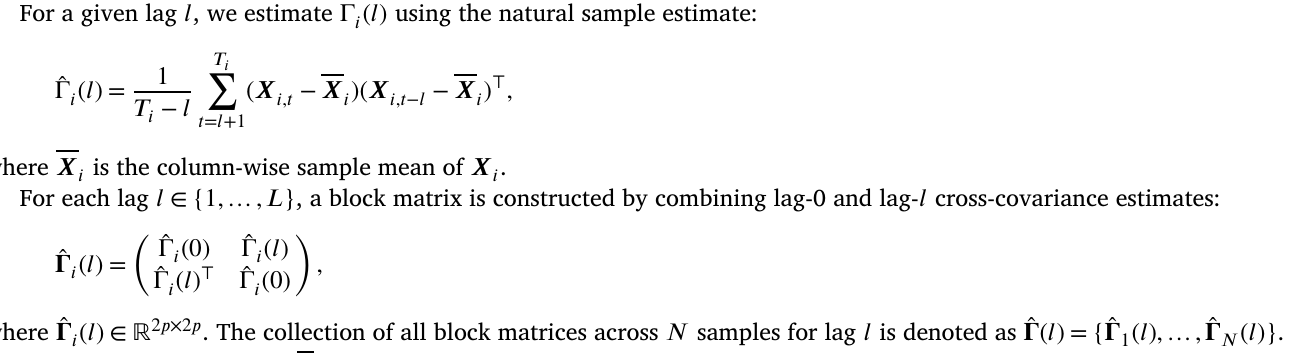

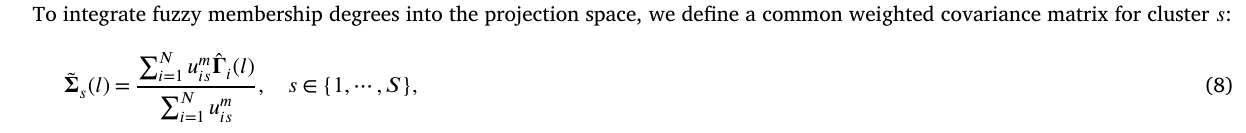

- i=1 to N number of samples for that subject
- t= 1 to 384 number of time points
- k(l) - index of selected eigenvectors
- p=30 number of time series/ channels
- l - lag (1 or 2 here)

### Function to calculate covariance matrix

In [ ]:
def compute_covariance_matrix(df, i, l, T_i=384):
    matrix = df[i-1]
    gamma_i_0 = (matrix.T @ matrix) / T_i
    current = matrix[l:]
    lagged = matrix[:-l]
    gamma_i_l = (lagged.T @ current) / (T_i - l)
    bold_gamma_i_l = np.block([[gamma_i_0,   gamma_i_l],[gamma_i_l.T, gamma_i_0]])
    return bold_gamma_i_l

def compute_common_matrix(df,l):
  gamma_l=[]
  for i in range(1,len(df)+1):
    gamma_l.append(compute_covariance_matrix(df,i,l))

  sigma_l=np.mean(np.array(gamma_l),axis=0)
  return sigma_l

## Calculate pca components to capture 95% variance for lag 1 and 2

In [ ]:
def calculate_pca_components(cov_matrix):
  eigenvalues,eigenvectors=np.linalg.eigh(cov_matrix)
  idx=np.argsort(eigenvalues)[::-1]
  eigenvalues_sorted=eigenvalues[idx]
  eigenvectors_sorted=eigenvectors[:,idx]
  variance=eigenvalues_sorted/np.sum(eigenvalues_sorted)
  cumulative_variance=np.cumsum(variance)
  pca_components = np.argmax(cumulative_variance >= 0.95) + 1

  top_eigenvalues = eigenvalues_sorted[:pca_components]
  top_eigenvectors = eigenvectors_sorted[:, :pca_components]
  return top_eigenvalues,top_eigenvectors,pca_components

In [ ]:
eigenvalues_lag1,eigenvectors_lag1,k_lag1={},{},{}
eigenvalues_lag2,eigenvectors_lag2,k_lag2={},{},{}
for i in range(1,12):
  df=normalised_grouped_eeg_data[i]
  block_covariance_matrix_lag1=compute_common_matrix(df,1)
  block_covariance_matrix_lag2=compute_common_matrix(df,2)
  eigenvalues_lag1_i,eigenvectors_lag1_i,k_lag1_i=calculate_pca_components(block_covariance_matrix_lag1)
  eigenvalues_lag2_i,eigenvectors_lag2_i,k_lag2_i=calculate_pca_components(block_covariance_matrix_lag2)
  eigenvalues_lag1[i]=eigenvalues_lag1_i
  eigenvectors_lag1[i]=eigenvectors_lag1_i
  k_lag1[i]=k_lag1_i
  eigenvalues_lag2[i]=eigenvalues_lag2_i
  eigenvectors_lag2[i]=eigenvectors_lag2_i
  k_lag2[i]=k_lag2_i


# Prepare concatenated inputs - current and lagged values

In [ ]:
def prepare_concatenated_inputs(X_list, l):
    X_hat = []
    for X in X_list:
        lagged = X[:-l]
        current = X[l:]
        X_hat.append(np.hstack((lagged, current)))

    return X_hat

# FCPCA : Fuzzy clustering of MTS based on CPCA
- Use grid search and Xie Beni and FS indices to find best value of m - fuzziness parameter
- Perform the algorithm on the best m
- For the best m, return the final membership matrix, reconstruction error, projection axes and the labels

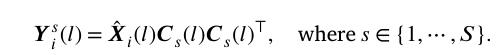

In [ ]:
def fcpca(X_list, gamma_dict, X_hat_dict, k_dict, S, m, L_max=2, max_iter=1000, R=3, tolerance=0.001):

  N = len(X_list)
  E_star = float('inf')
  U_star , C_star = None, None

  for r in range(R):
    #initialize U (N x S) randomly, initialise E -> inf, iteration counter t = 0
    E = 1e9
    t = 0
    U = np.random.rand(N, S)
    U = U/U.sum(axis = 1, keepdims = True) #normalise rows to sum to 1
    E_prev = float('inf')

    while t<max_iter:
      C = {s: {} for s in range(S)}

      for l in range(1, L_max+1):
        for s in range(S):
          weights =U[:,s]**m
          Sigma_tilde_s_l = sum(weights[i]*gamma_dict[l][i] for i in range(N))/np.sum(weights)
          eigenvalues, eigenvectors = np.linalg.eigh(Sigma_tilde_s_l)
          idx = np.argsort(eigenvalues)[::-1]
          top_eigenvectors = eigenvectors[:, idx][:, :k_dict[l]]
          C[s][l] = top_eigenvectors

      error_matrix = np.zeros((N, S))
      for i in range (N):
        for s in range(S):
          err_sum = 0
          for l in range(1, L_max+1):
            X_hat = X_hat_dict[l][i]
            C_sl = C[s][l]

            projection = X_hat@C_sl@C_sl.T

            err_sum += np.linalg.norm(X_hat - projection, ord = "fro")**2

          error_matrix[i, s] = err_sum + 1e-10

      E = np.sum((U**m)*error_matrix)

      if(abs(E_prev -E) < tolerance):
        break
      E_prev =E

      ratio_matrix = error_matrix[:,:,np.newaxis] / error_matrix[:, np.newaxis, :]
      U = 1.0/np.sum(ratio_matrix** (1.0/(m-1)), axis=2)

      t+=1

    if E < E_star:
      E_star =E
      U_star = U
      C_star = C

  hard_labels = np.argmax(U_star, axis = 1)


  return U_star, C_star, E_star, hard_labels


# Cluster validity indices (CVIs)
- They are used to find best value for fuzziness parameter.
- The lower the Xie beni index the better
- The higher the FS index the better

## Xie-Beni (XB) and Fuzzy Silhouette (FS) index

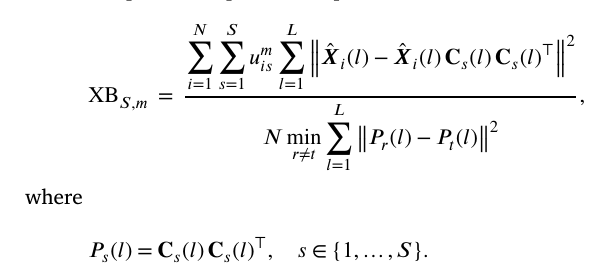

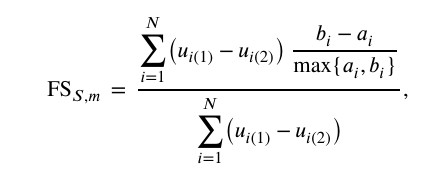

In [ ]:
def compute_XB(X_hat_dict, C_star, U_star, E_star, m, S, L_max=2):
  N = U_star.shape[0]

  min_P_dist  =float('inf')
  for s in range(S):
    for s_prime in range(s+1, S):
      dist = 0
      for l in range(1, L_max+1):
        P_s = C_star[s][l]@C_star[s][l].T
        P_s_prime = C_star[s_prime][l]@C_star[s_prime][l].T

        dist+= np.linalg.norm(P_s - P_s_prime, ord = 'fro')**2

      if dist <min_P_dist:
        min_P_dist = dist

  if(min_P_dist==0):
    XB = float('inf')
  else :
    XB = E_star/(N*min_P_dist)

  return XB

def compute_FS(X_hat_dict, C_star, U_star, E_star, m, S, L_max=2):
  N = U_star.shape[0]
  error_matrix = np.zeros((N,S))
  for i in range (N):
    for s in range(S):
      err_sum = 0
      for l in range(1, L_max+1):
        X_hat = X_hat_dict[l][i]
        C_sl = C_star[s][l]

        projection = X_hat@C_sl@C_sl.T

        err_sum += np.linalg.norm(X_hat - projection, ord = "fro")**2

      error_matrix[i, s] = err_sum + 1e-10

  FS_num = 0
  FS_den = 0

  for i in range(N):
    #intracluster reconstruction error
    errors = error_matrix[i]
    z_i = np.argmin(errors)
    a_i = errors[z_i]

    #smallest reconstruction error among all other clusters
    other_errors = np.delete(errors, z_i)
    b_i = np.min(other_errors)

    #largest and second largest membership degrees

    u_sorted = np.sort(U_star[i])[::-1]
    u_1, u_2 = u_sorted[0], u_sorted[1]

    #confidence weight
    weight = u_1-u_2
    max_ab = max(a_i, b_i)

    if (max_ab > 0):
      FS_num += weight*((b_i-a_i)/max_ab)
    FS_den += weight

  FS = FS_num/FS_den if FS_den>0 else 0
  return FS

# Grid search for optimal fuzziness parameter (m)

In [ ]:
def grid_search_fcpca(X_list, gamma_dict, X_hat_dict, k_dict, S, L_max=2):
   #m ranges from 1.1 to 2.2
    m_values = np.arange(1.1, 2.3, 0.1)

    best_m = None
    best_XB = float('inf')
    best_FS = -float('inf')
    best_U = None
    best_C = None
    best_labels = None
    best_E = None
    grid_results = {}

    for m in m_values:
        m = round(m, 2)
        U_star, C_star, E_star, hard_labels = fcpca(X_list, gamma_dict, X_hat_dict, k_dict, S, m, L_max=L_max)
        XB = compute_XB(X_hat_dict, C_star, U_star, E_star, m, S, L_max=L_max)
        FS = compute_FS(X_hat_dict, C_star, U_star, E_star, m, S, L_max=L_max)

        grid_results[m] = {'XB': XB, 'FS': FS, 'E_star': E_star}

        # Select m that minimizes XB and maximizes FS.
        #If they disagree, prioritize the lower XB index
        is_better_XB = XB < best_XB
        is_tie_XB = np.isclose(XB, best_XB, rtol=1e-05, atol=1e-08)
        is_better_FS = FS > best_FS

        if is_better_XB or (is_tie_XB and is_better_FS):
            best_XB = XB
            best_FS = FS
            best_m = m
            best_U = U_star
            best_C = C_star
            best_labels = hard_labels
            best_E = E_star

    print(f"Optimal m selected: {best_m} (XB: {best_XB:.4f}, FS: {best_FS:.4f})")

    return best_m, best_U, best_C, best_labels, best_E, grid_results

# Calculate Rand score (Evaluation) - Same as pairwise accuracy

In [ ]:
from sklearn.metrics import adjusted_rand_score

def calculate_rand_index(true_labels, pred_labels):
    n = len(true_labels)
    if n < 2: return 0.0

    tp_plus_fp = np.sum([len(np.where(pred_labels == i)[0]) * (len(np.where(pred_labels == i)[0]) - 1)/2 for i in np.unique(pred_labels)])
    tp_plus_fn = np.sum([len(np.where(true_labels == i)[0]) * (len(np.where(true_labels == i)[0]) - 1) / 2 for i in np.unique(true_labels)])

    tp = 0
    for c1 in np.unique(true_labels):
        for c2 in np.unique(pred_labels):
            count = len(np.intersect1d(np.where(true_labels == c1)[0], np.where(pred_labels == c2)[0]))
            tp += count * (count - 1) / 2

    fp = tp_plus_fp-tp
    fn = tp_plus_fn-tp
    tn = (n * (n-1)/2)-tp-fp-fn

    return (tp+tn)/(tp+fp+fn+tn)


# Run the algorithm on each subject

In [ ]:
S = 2
L_max = 2
threshold = 0.7

all_subject_results = []

for subject_id in range(1, 12):
    print(f"\n--- Processing Subject {subject_id} ---")

    subject_df = grouped_eeg_df[subject_id]
    true_labels = subject_df['substate'].values

    X_list = normalised_grouped_eeg_data[subject_id]

    gamma_dict = {1: [compute_covariance_matrix(X_list, i, 1) for i in range(1, len(X_list)+1)],2: [compute_covariance_matrix(X_list, i, 2) for i in range(1, len(X_list)+1)]}
    k_dict = {1: k_lag1[subject_id],
        2: k_lag2[subject_id]}

    # Prepare concatenated inputs for this subject
    X_hat_dict = {1: prepare_concatenated_inputs(X_list, 1),
        2: prepare_concatenated_inputs(X_list, 2)}

    #Run Grid Search to find optimal m and best models
    best_m, best_U, best_C, hard_labels, best_E, grid_results = grid_search_fcpca(X_list, gamma_dict, X_hat_dict, k_dict, S, L_max=L_max)

    #Apply Threshold for Fuzzy/Mixed States
    final_labels = np.zeros(len(best_U), dtype=int)
    mixed_count = 0

    for i in range(len(best_U)):
        if best_U[i, 0] >= threshold:
            final_labels[i] = 0
        elif best_U[i, 1] >= threshold:
            final_labels[i] = 1
        else:
            final_labels[i] = 2
            mixed_count += 1

    print(f"Detected {mixed_count} mixed/transitional states out of {len(best_U)} samples.")

    #Evaluate using RI and ARI
    valid_indices = np.where(final_labels != 2)[0]
    filtered_true = true_labels[valid_indices]
    filtered_pred = final_labels[valid_indices]

    ri_score = calculate_rand_index(filtered_true, filtered_pred)
    ari_score = adjusted_rand_score(filtered_true, filtered_pred)

    print(f"Rand Index (RI): {ri_score:.4f}")
    print(f"Adjusted Rand Index (ARI): {ari_score:.4f}")

    all_subject_results.append({
        'Subject': subject_id,
        'Optimal_m': best_m,
        'Mixed_States': mixed_count,
        'Total_Samples': len(best_U),
        'RI': ri_score,
        'ARI': ari_score})

results_df = pd.DataFrame(all_subject_results)
display(results_df)


--- Processing Subject 1 ---
Optimal m selected: 1.1 (XB: 210.7866, FS: 0.3283)
Detected 68 mixed/transitional states out of 188 samples.
Rand Index (RI): 0.5518
Adjusted Rand Index (ARI): 0.1036

--- Processing Subject 2 ---
Optimal m selected: 2.2 (XB: 110.5917, FS: 0.3713)
Detected 131 mixed/transitional states out of 132 samples.
Rand Index (RI): 0.0000
Adjusted Rand Index (ARI): 1.0000

--- Processing Subject 3 ---
Optimal m selected: 2.2 (XB: 52.5466, FS: 0.5894)
Detected 135 mixed/transitional states out of 150 samples.
Rand Index (RI): 0.5810
Adjusted Rand Index (ARI): 0.0000

--- Processing Subject 4 ---
Optimal m selected: 2.2 (XB: 32.8328, FS: 0.5877)
Detected 134 mixed/transitional states out of 148 samples.
Rand Index (RI): 0.8571
Adjusted Rand Index (ARI): 0.6717

--- Processing Subject 5 ---
Optimal m selected: 1.1 (XB: 85.7239, FS: 0.4936)
Detected 3 mixed/transitional states out of 224 samples.
Rand Index (RI): 0.4990
Adjusted Rand Index (ARI): 0.0015

--- Processing 

,Subject,Optimal_m,Mixed_States,Total_Samples,RI,ARI
0,1,1.1,68,188,0.551821,0.103627
1,2,2.2,131,132,0.000000,1.000000
2,3,2.2,135,150,0.580952,0.000000
3,4,2.2,134,148,0.857143,0.671663
4,5,1.1,3,224,0.498972,0.001541
5,6,1.1,3,166,0.497387,-0.004382
6,7,1.1,19,102,0.502792,0.008990
7,8,1.1,17,264,0.532734,0.066551
8,9,1.1,2,314,0.499402,0.001356
9,10,1.1,108,108,0.000000,1.000000


### Function to plot membership matrix

In [ ]:
import matplotlib.pyplot as plt
def plot_membership_matrix(U, subject_id, m_val):
    N = U.shape[0]
    samples = np.arange(N)
    fig, ax = plt.subplots(figsize=(14, 6))
    ax.bar(samples, U[:, 0], color='#8AB1B0', label='Alert State', width=1.0)
    ax.bar(samples, U[:, 1], bottom=U[:, 0], color='#FFB6C1', label='Drowsy State', width=1.0)

    ax.set_xlim([0, N])
    ax.set_ylim([0, 1.0])
    ax.set_xlabel("Sample", fontsize=12)
    ax.set_ylabel("Membership Degree", fontsize=12)
    ax.set_title(f"Membership Matrix of Samples for Subject {subject_id} (m = {m_val})", fontsize=14)
    ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), title="Group")

    plt.tight_layout()
    plt.show()

### Plotting memebership matrix for subject 11

Optimal m selected: 1.1 (XB: 170.7741, FS: 0.2682)
Optimal Fuzziness (m): 1.1
Transitional/Mixed States Detected: 37 out of 226 samples
Adjusted Rand Index (ARI) on crisp states: 0.1338


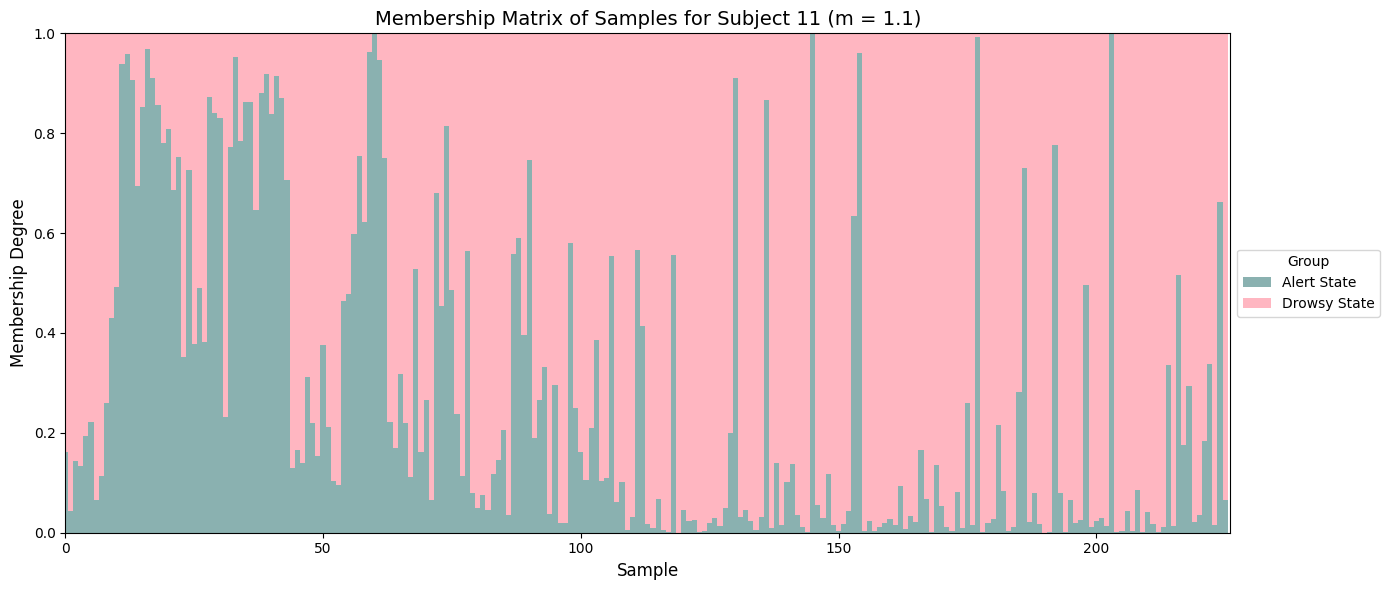

In [ ]:
subject_id = 11
S = 2
L_max = 2
threshold = 0.7


# Extract normalized data
X_list = normalised_grouped_eeg_data[subject_id]
true_labels = grouped_eeg_df[subject_id]['substate'].values
block_cov_lag1 = compute_common_matrix(X_list, 1)
block_cov_lag2 = compute_common_matrix(X_list, 2)

_, _, k_lag1_corr = calculate_pca_components(block_cov_lag1)
_, _, k_lag2_corr = calculate_pca_components(block_cov_lag2)

gamma_dict_corr = {1: [compute_covariance_matrix(X_list, i, 1) for i in range(1, len(X_list)+1)],2: [compute_covariance_matrix(X_list, i, 2) for i in range(1, len(X_list)+1)]}
k_dict_corr = {1: k_lag1_corr, 2: k_lag2_corr}

X_hat_dict = {1: prepare_concatenated_inputs(X_list, 1),2: prepare_concatenated_inputs(X_list, 2)}

# Run Grid Search
best_m, best_U, best_C, hard_labels, best_E, grid_results = grid_search_fcpca(X_list, gamma_dict_corr, X_hat_dict, k_dict_corr, S, L_max=L_max)

# 0 = Alert, 1 = Drowsy in the dataset
cluster_0_as_alert = np.sum((hard_labels == 0) & (true_labels == 0)) + np.sum((hard_labels == 1) & (true_labels == 1))
cluster_1_as_alert = np.sum((hard_labels == 1) & (true_labels == 0)) + np.sum((hard_labels == 0) & (true_labels == 1))

if cluster_1_as_alert > cluster_0_as_alert:
    # Swap columns in U so Column 0 is always Alert
    best_U = best_U[:, [1, 0]]
    hard_labels = 1 - hard_labels

# Apply mixed transition threshold
final_labels = np.zeros(len(best_U), dtype=int)
mixed_count = 0
for i in range(len(best_U)):
    if best_U[i, 0] >= threshold:
        final_labels[i] = 0
    elif best_U[i, 1] >= threshold:
        final_labels[i] = 1
    else:
        final_labels[i] = 2
        mixed_count += 1

# Output
valid_indices = np.where(final_labels != 2)[0]
ari_score = adjusted_rand_score(true_labels[valid_indices], final_labels[valid_indices])

print(f"Optimal Fuzziness (m): {best_m}")
print(f"Transitional/Mixed States Detected: {mixed_count} out of {len(best_U)} samples")
print(f"Adjusted Rand Index (ARI) on crisp states: {ari_score:.4f}")

plot_membership_matrix(best_U, subject_id, best_m)

### Plotting ARI and RI

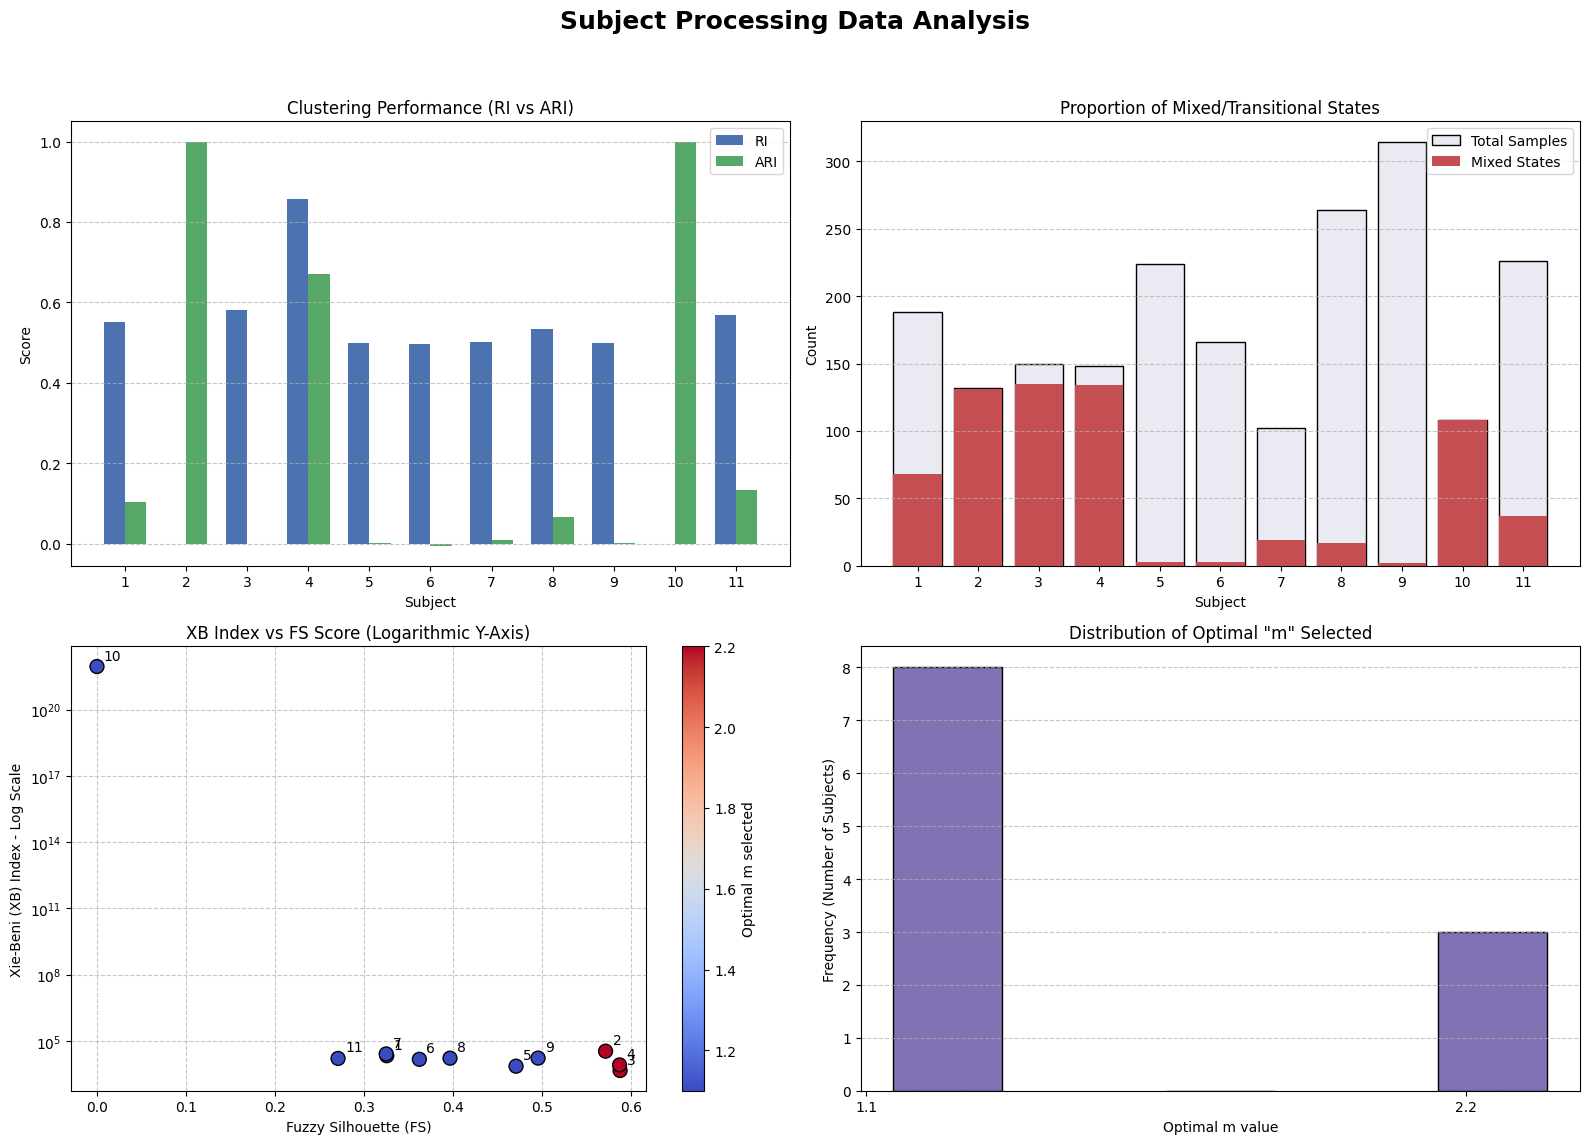

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if 'FS' not in results_df.columns and 'XB' not in results_df.columns:
    results_df['XB'] = [20874.9186, 33562.6962, 4454.6090, 7975.6122, 6985.5117, 14362.8870,
                         25166.6169, 16177.3791, 16294.8682, 9.039e21, 15736.4099]
    results_df['FS'] = [0.3256, 0.5715, 0.5878, 0.5872, 0.4709, 0.3623, 0.3250, 0.3967, 0.4957, 0.0000, 0.2709]

fig, axs = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Subject Processing Data Analysis', fontsize=18, fontweight='bold')
x = np.arange(len(results_df))

width = 0.35
axs[0, 0].bar(x - width/2, results_df['RI'], width, label='RI', color='#4C72B0')
axs[0, 0].bar(x + width/2, results_df['ARI'], width, label='ARI', color='#55A868')
axs[0, 0].set_title('Clustering Performance (RI vs ARI)')
axs[0, 0].set_xlabel('Subject')
axs[0, 0].set_ylabel('Score')
axs[0, 0].set_xticks(x)
axs[0, 0].set_xticklabels(results_df['Subject'].astype(str))
axs[0, 0].legend()
axs[0, 0].grid(axis='y', linestyle='--', alpha=0.7)

axs[0, 1].bar(x,results_df['Total_Samples'],label='Total Samples',color='#EAEAF2',edgecolor='black',)
axs[0, 1].bar(x, results_df['Mixed_States'], label='Mixed States', color='#C44E52')
axs[0, 1].set_title('Proportion of Mixed/Transitional States')
axs[0, 1].set_xlabel('Subject')
axs[0, 1].set_ylabel('Count')
axs[0, 1].set_xticks(x)
axs[0, 1].set_xticklabels(results_df['Subject'].astype(str))
axs[0, 1].legend()
axs[0, 1].grid(axis='y', linestyle='--', alpha=0.7)

scatter = axs[1, 0].scatter(results_df['FS'],results_df['XB'],c=results_df['Optimal_m'],cmap='coolwarm',s=100,edgecolor='black',zorder=5,)
axs[1, 0].set_yscale('log')
axs[1, 0].set_title('XB Index vs FS Score (Logarithmic Y-Axis)')
axs[1, 0].set_xlabel('Fuzzy Silhouette (FS)')
axs[1, 0].set_ylabel('Xie-Beni (XB) Index - Log Scale')
axs[1, 0].grid(True, linestyle='--', alpha=0.7)
cbar = plt.colorbar(scatter, ax=axs[1, 0])
cbar.set_label('Optimal m selected')

for idx, row in results_df.iterrows():
  axs[1, 0].annotate(
      str(int(row['Subject'])),
      (row['FS'], row['XB']),
      xytext=(5, 5),
      textcoords='offset points',
  )

unique_m = sorted(results_df['Optimal_m'].unique())
axs[1, 1].hist(results_df['Optimal_m'],bins=[1.0, 1.5, 2.0, 2.5],color='#8172B3',edgecolor='black',rwidth=0.4,)
axs[1, 1].set_title('Distribution of Optimal "m" Selected')
axs[1, 1].set_xlabel('Optimal m value')
axs[1, 1].set_ylabel('Frequency (Number of Subjects)')
axs[1, 1].set_xticks([1.1, 2.2])
axs[1, 1].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()